# PartialSpoof v1.2 — CNN Training Pipeline **v3 (class-imbalance + crop fix)**

Corrected version of `PartialSpoof_v1_2_Optimized_Debug_Training_v2`.

## Why v2 failed (diagnosis from the logs)

| # | Problem in v2 | Evidence | Fix in v3 |
|---|---|---|---|
| 1 | **Crop bug**: `4.0 * 16000 / 10 / 1000 = 6.4` → training crops were **6 frames (60 ms)**, not 400 | batch shape `(4, 1, 80, 6)` | `CROP_FRAMES = TRAIN_CROP_SEC*1000/HOP_MS = 400` (asserted) |
| 2 | **No class-imbalance handling** (≈ 90 % spoof / 10 % bona-fide utterances) | Precision = Accuracy = 0.89744 = dev spoof fraction, Recall = 1.0, F1 constant for 13 epochs; train loss ≈ 0.31 ≈ entropy of the 90/10 prior | balanced sampler (default) **or** `pos_weight`; metrics that expose collapse |
| 3 | Utterance label put on a random crop (often contained **no** spoof) | label-aware crop was never implemented | crop label is derived from the official 20 ms segment labels; spoof-containing crops are oversampled |
| 4 | Label polarity of segment files assumed (`1 = spoof`) | never verified | polarity is **detected from bona-fide utterances** and asserted |
| 5 | Batch size 4 with BatchNorm, full-length dev batches padded randomly | erratic dev EER 20 % ↔ 40 % | batch 16; dev batches are length-sorted |
| 6 | Only accuracy / F1 @ 0.5 monitored | looked "fine" (F1 = 0.946) while the model predicted one class | bona-fide recall, spoof recall, balanced accuracy, % predicted spoof, confusion matrix every epoch |
| 7 | Wrong checkpoint inspected (`baseline_logmel_debug`) | cell 65 of v2 | evaluation cell uses the path returned by the run |

The notebook is now **linear** (v2 had cells that used `dev_loader` / `predict_utterance` before they were defined).
Exploration-only cells (directory dump, `.npy` inspector) were removed.

## Run order
Run top-to-bottom. Run the **smoke test** before the full run: it must show the model predicting *both* classes.

# A. Environment

In [1]:
# ============================================================
# 1. INSTALL DEPENDENCIES
# ============================================================
%pip install -q numpy pandas scipy scikit-learn matplotlib seaborn librosa soundfile tqdm pyyaml psutil

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ============================================================
# 2. IMPORTS + VERSION DEBUG
# ============================================================
import os
import sys
import json
import math
import time
import random
import hashlib
import shutil
import gc
import warnings
import subprocess
import platform
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Optional
import itertools
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler, WeightedRandomSampler, RandomSampler

from sklearn.metrics import (
    roc_curve, roc_auc_score, average_precision_score,
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix
)

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Librosa:", librosa.__version__)
print("Platform:", platform.platform())

C:\Users\Dhanshree\.conda\envs\partialspoof\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]
PyTorch: 2.13.0+cpu
NumPy: 2.4.6
Pandas: 3.0.5
Librosa: 0.11.0
Platform: Windows-10-10.0.26100-SP0


In [3]:
# ============================================================
# 3. CONFIGURATION
# ============================================================
@dataclass
class CFG:
    # ---------- paths ----------
    PS_ROOT: str = r"D:\PartialSpoofExtract"
    OUTPUT_ROOT: str = r"./runs/partialspoof_v3"
    CACHE_ROOT: str = r"./cache/partialspoof_v2"      # re-uses the Log-Mel cache you already built

    # ---------- reproducibility ----------
    SEED: int = 42
    DETERMINISTIC: bool = False

    # ---------- audit/debug ----------
    DEBUG_MODE: bool = False
    DEBUG_FILES_PER_SPLIT: int = 32
    FAIL_ON_AUDIT_ERROR: bool = True

    # ---------- hardware ----------
    BATCH_SIZE: int = 16            # v2 used 4 (too small for BatchNorm)
    EVAL_BATCH_SIZE: int = 32
    NUM_WORKERS: int = 0            # keep 0 on Windows notebooks
    PIN_MEMORY: bool = True

    # ---------- training ----------
    EPOCHS: int = 20
    SAMPLES_PER_EPOCH: int = 10000  # one "epoch" = this many randomly drawn utterances
    LR: float = 2e-4
    WEIGHT_DECAY: float = 1e-4
    PATIENCE: int = 5
    GRAD_ACCUM_STEPS: int = 1
    GRAD_CLIP: float = 5.0

    # ---------- class imbalance ----------
    # "sampler"    : WeightedRandomSampler -> ~50/50 utterances per batch (default, no loss weighting)
    # "pos_weight" : natural sampling + BCE pos_weight = n_bonafide / n_spoof
    # "none"       : v2 behaviour (will collapse - only for comparison)
    IMBALANCE_MODE: str = "sampler"

    # ---------- audio ----------
    TARGET_SR: int = 16000
    ALLOW_RESAMPLE: bool = True

    # ---------- feature extraction (UNCHANGED -> cache stays valid) ----------
    N_FFT: int = 512
    WIN_MS: float = 20.0
    HOP_MS: float = 10.0
    N_MELS: int = 80
    LFCC_FILTERS: int = 80
    LFCC_COEFFS: int = 40
    CQT_BINS_PER_OCTAVE: int = 12
    CQT_N_BINS: int = 84
    CQT_FMIN: float = 20.0

    # ---------- model ----------
    BASE_CHANNELS: int = 32
    EMBED_DIM: int = 128
    DROPOUT: float = 0.20

    # ---------- training crop ----------
    TRAIN_CROP_SEC: float = 4.0
    SPOOF_CROP_PROB: float = 0.7        # P(crop is centred on a spoofed region) for spoofed utterances
    MIN_SPOOF_FRAMES_IN_CROP: int = 5   # >= 50 ms of spoof inside the crop -> crop label = spoof

    # ---------- dev monitoring ----------
    DEV_EPOCH_PER_CLASS: int = 1500     # per-epoch DEV uses a class-balanced subset (EER is prevalence independent)

    # ---------- views ----------
    DEFAULT_FEATURES: tuple = ("logmel",)
    RESOLUTIONS_MS: tuple = (20, 40, 80, 160, 320, 640)

    # ---------- EVAL safety ----------
    ALLOW_EVAL: bool = False


cfg = CFG()

OUT = Path(cfg.OUTPUT_ROOT);   OUT.mkdir(parents=True, exist_ok=True)
CACHE = Path(cfg.CACHE_ROOT);  CACHE.mkdir(parents=True, exist_ok=True)

# ---- THE v2 BUG: this used to be  TRAIN_CROP_SEC * TARGET_SR / HOP_MS / 1000 = 6 frames ----
CROP_FRAMES = int(round(cfg.TRAIN_CROP_SEC * 1000.0 / cfg.HOP_MS))
assert CROP_FRAMES == 400, f"unexpected crop length {CROP_FRAMES}"
assert cfg.IMBALANCE_MODE in ("sampler", "pos_weight", "none")

print(json.dumps(asdict(cfg), indent=2, default=str))
print("CROP_FRAMES =", CROP_FRAMES, f"({CROP_FRAMES * cfg.HOP_MS / 1000:.1f} s)")

{
  "PS_ROOT": "D:\\PartialSpoofExtract",
  "OUTPUT_ROOT": "./runs/partialspoof_v3",
  "CACHE_ROOT": "./cache/partialspoof_v2",
  "SEED": 42,
  "DETERMINISTIC": false,
  "DEBUG_MODE": false,
  "DEBUG_FILES_PER_SPLIT": 32,
  "FAIL_ON_AUDIT_ERROR": true,
  "BATCH_SIZE": 16,
  "EVAL_BATCH_SIZE": 32,
  "NUM_WORKERS": 0,
  "PIN_MEMORY": true,
  "EPOCHS": 20,
  "SAMPLES_PER_EPOCH": 10000,
  "LR": 0.0002,
  "WEIGHT_DECAY": 0.0001,
  "PATIENCE": 5,
  "GRAD_ACCUM_STEPS": 1,
  "GRAD_CLIP": 5.0,
  "IMBALANCE_MODE": "sampler",
  "TARGET_SR": 16000,
  "ALLOW_RESAMPLE": true,
  "N_FFT": 512,
  "WIN_MS": 20.0,
  "HOP_MS": 10.0,
  "N_MELS": 80,
  "LFCC_FILTERS": 80,
  "LFCC_COEFFS": 40,
  "CQT_BINS_PER_OCTAVE": 12,
  "CQT_N_BINS": 84,
  "CQT_FMIN": 20.0,
  "BASE_CHANNELS": 32,
  "EMBED_DIM": 128,
  "DROPOUT": 0.2,
  "TRAIN_CROP_SEC": 4.0,
  "SPOOF_CROP_PROB": 0.7,
  "MIN_SPOOF_FRAMES_IN_CROP": 5,
  "DEV_EPOCH_PER_CLASS": 1500,
  "DEFAULT_FEATURES": [
    "logmel"
  ],
  "RESOLUTIONS_MS": [
    20,
   

In [4]:
# ============================================================
# 4. SEED + DEVICE + GPU DEBUG
# ============================================================
def seed_everything(seed=42, deterministic=False):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

seed_everything(cfg.SEED, cfg.DETERMINISTIC)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("DEVICE:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print(f"VRAM total: {props.total_memory / 1024**3:.2f} GB")
    print("CUDA:", torch.version.cuda)
    torch.cuda.reset_peak_memory_stats()
else:
    print("WARNING: CPU-only mode. Full training will be substantially slower.")

AMP_ENABLED = DEVICE.type == "cuda"
print("AMP enabled:", AMP_ENABLED)

print('torch threads:', torch.get_num_threads())

DEVICE: cpu
AMP enabled: False
torch threads: 6


# B. Dataset audit

In [5]:
# ============================================================
# 5. VERIFY DATASET ROOT + EXPECTED STRUCTURE
# ============================================================
PS_ROOT = Path(cfg.PS_ROOT)

if not PS_ROOT.exists():
    raise FileNotFoundError(
        f"PS_ROOT does not exist: {PS_ROOT}\n"
        "Change CFG.PS_ROOT to your extracted PartialSpoof v1.2 repository/database."
    )

print("Dataset root:", PS_ROOT.resolve())

for p in [
    "database",
    "database/train",
    "database/dev",
    "database/eval",
    "database/protocols",
    "database/segment_labels",
    "database/vad",
]:
    target = PS_ROOT / p
    print(f"{'OK' if target.exists() else 'MISSING':8s} {target}")

Dataset root: D:\PartialSpoofExtract
OK       D:\PartialSpoofExtract\database
OK       D:\PartialSpoofExtract\database\train
OK       D:\PartialSpoofExtract\database\dev
OK       D:\PartialSpoofExtract\database\eval
OK       D:\PartialSpoofExtract\database\protocols
OK       D:\PartialSpoofExtract\database\segment_labels
OK       D:\PartialSpoofExtract\database\vad



database/train
File count: 25381
   database\train\train.lst
   database\train\con_wav\CON_T_0000000.wav
   database\train\con_wav\CON_T_0000001.wav
   database\train\con_wav\CON_T_0000002.wav
   database\train\con_wav\CON_T_0000003.wav

database/dev
File count: 24845
   database\dev\dev.lst
   database\dev\con_wav\CON_D_0000000.wav
   database\dev\con_wav\CON_D_0000001.wav
   database\dev\con_wav\CON_D_0000002.wav
   database\dev\con_wav\CON_D_0000003.wav

database/eval
File count: 71239
   database\eval\eval.lst
   database\eval\eval_clean.lst
   database\eval\con_wav\CON_E_0000000.wav
   database\eval\con_wav\CON_E_0000001.wav
   database\eval\con_wav\CON_E_0000002.wav

database/protocols
File count: 27
   database\protocols\ASVspoof2019_LA_asv_protocols\ASVspoof2019.LA.asv.dev.female.trl.txt
   database\protocols\ASVspoof2019_LA_asv_protocols\ASVspoof2019.LA.asv.dev.female.trn.txt
   database\protocols\ASVspoof2019_LA_asv_protocols\ASVspoof2019.LA.asv.dev.gi.trl.txt
   database\pr

In [7]:
# ============================================================
# 6. INSPECT DATASET LISTS AND SEGMENT LABELS
# ============================================================
import numpy as np
from pathlib import Path

PS_ROOT = Path(cfg.PS_ROOT)
DB_ROOT = PS_ROOT / "database"

# 1. Inspect train/dev/eval list files
for split in ["train", "dev", "eval"]:
    lst_file = DB_ROOT / split / f"{split}.lst"

    print(f"\n--- {split.upper()} LIST ---")
    if lst_file.exists():
        with open(lst_file, "r", encoding="utf-8", errors="replace") as f:
            for i, line in enumerate(f):
                if i >= 5:
                    break
                print(repr(line.rstrip()))
    else:
        print("List file not found:", lst_file)

# 2. Inspect segment-label NumPy files
label_dir = DB_ROOT / "segment_labels"

print("\n--- SEGMENT LABEL FILES ---")
for label_file in sorted(label_dir.glob("*.npy"))[:5]:
    try:
        arr = np.load(label_file, allow_pickle=False)
        print(
            label_file.name,
            "| shape:", arr.shape,
            "| dtype:", arr.dtype,
            "| sample:", arr.reshape(-1)[:10]
        )
    except Exception as e:
        print(label_file.name, "| ERROR:", e)


--- TRAIN LIST ---
'LA_T_1000406'
'LA_T_1007571'
'LA_T_1007663'
'LA_T_1011221'
'LA_T_1013597'

--- DEV LIST ---
'LA_D_1024892'
'LA_D_1026868'
'LA_D_1028589'
'LA_D_1038259'
'LA_D_1047731'

--- EVAL LIST ---
'LA_E_1002903'
'LA_E_1003128'
'LA_E_1004363'
'LA_E_1005795'
'LA_E_1007872'

--- SEGMENT LABEL FILES ---
dev_seglab_0.01.npy | ERROR: Object arrays cannot be loaded when allow_pickle=False
dev_seglab_0.02.npy | ERROR: Object arrays cannot be loaded when allow_pickle=False
dev_seglab_0.04.npy | ERROR: Object arrays cannot be loaded when allow_pickle=False
dev_seglab_0.08.npy | ERROR: Object arrays cannot be loaded when allow_pickle=False
dev_seglab_0.16.npy | ERROR: Object arrays cannot be loaded when allow_pickle=False


In [8]:
# ============================================================
# 7. INSPECT LABEL STRUCTURE AND AUDIO MAPPING
# ============================================================
import numpy as np
from pathlib import Path

DB_ROOT = Path(cfg.PS_ROOT) / "database"

# A. Inspect segment-label arrays
label_dir = DB_ROOT / "segment_labels"

for label_file in sorted(label_dir.glob("*.npy"))[:3]:
    print(f"\n--- {label_file.name} ---")

    try:
        # Use only because these files are from your trusted dataset.
        arr = np.load(label_file, allow_pickle=True)

        print("Type:", type(arr))
        print("Shape:", arr.shape)
        print("Dtype:", arr.dtype)

        if arr.dtype == object:
            print("Object-array item count:", arr.size)
            if arr.size:
                print("First item:", repr(arr.flat[0])[:500])
        else:
            print("Sample:", arr.reshape(-1)[:10])

    except Exception as e:
        print("Error:", repr(e))

# B. Inspect actual WAV names in each split
for split in ["train", "dev", "eval"]:
    wav_dir = DB_ROOT / split / "con_wav"
    print(f"\n--- {split.upper()} AUDIO ---")
    print("Audio folder exists:", wav_dir.exists())

    if wav_dir.exists():
        wav_files = list(wav_dir.glob("*.wav"))
        print("WAV count:", len(wav_files))
        print("First 5 WAV names:", [p.name for p in wav_files[:5]])

# C. Check whether the first list IDs match WAV filenames
for split in ["train", "dev", "eval"]:
    lst_file = DB_ROOT / split / f"{split}.lst"
    wav_dir = DB_ROOT / split / "con_wav"

    if lst_file.exists() and wav_dir.exists():
        with open(lst_file, encoding="utf-8") as f:
            ids = [line.strip() for line in f if line.strip()]

        wav_names = {p.stem for p in wav_dir.glob("*.wav")}

        matches = sum(item in wav_names for item in ids[:100])

        print(
            f"\n{split.upper()}: "
            f"{matches}/{min(100, len(ids))} initial IDs "
            "match con_wav filenames directly."
        )


--- dev_seglab_0.01.npy ---
Type: <class 'numpy.ndarray'>
Shape: ()
Dtype: object
Object-array item count: 1
First item: defaultdict(<class 'list'>, {'LA_D_1024892': array(['1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',
       '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',
       '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',
       '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',
       '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',
       '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',
       '1', '1', '1', '

--- dev_seglab_0.02.npy ---
Type: <class 'numpy.ndarray'>
Shape: ()
Dtype: object
Object-array item count: 1
First item: defaultdict(<class 'list'>, {'LA_D_1024892': array(['1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',
       '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',
       '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1', '1',

In [9]:
# ============================================================
# 7. AUDIO DISCOVERY
# ============================================================
def discover_audio(split):
    base = PS_ROOT / "database" / split
    files = sorted(list(base.rglob("*.wav")) + list(base.rglob("*.flac")))
    return files

split_files = {
    s: discover_audio(s)
    for s in ("train", "dev", "eval")
}

for split, files in split_files.items():
    print(f"{split:5s}: {len(files):,}")

assert all(len(v) > 0 for v in split_files.values()), "At least one split contains no audio."

train: 25,380
dev  : 24,844
eval : 71,237


In [11]:
# ============================================================
# 8. VERIFY LABEL IDS AND FIND MAPPING INFORMATION
# ============================================================
import numpy as np
from pathlib import Path

DB_ROOT = Path(cfg.PS_ROOT) / "database"

# 1. Compare list IDs with segment-label dictionary keys
for split in ["train", "dev", "eval"]:
    list_file = DB_ROOT / split / f"{split}.lst"

    with open(list_file, encoding="utf-8") as f:
        ids = [line.strip() for line in f if line.strip()]

    print(f"\n--- {split.upper()} ---")
    print("List IDs:", len(ids))
    print("First IDs:", ids[:3])

    label_files = sorted(
        (DB_ROOT / "segment_labels").glob(f"{split}_seglab_*.npy")
    )

    if label_files:
        data = np.load(label_files[0], allow_pickle=True).item()
        label_ids = set(data.keys())
        list_ids = set(ids)

        print("Label dictionary IDs:", len(label_ids))
        print("List IDs present in labels:", len(list_ids & label_ids))
        print("List IDs missing from labels:", len(list_ids - label_ids))
        print("Example label IDs:", list(label_ids)[:3])

        for uid in list(list_ids & label_ids)[:1]:
            labels = np.asarray(data[uid]).reshape(-1)
            print("Example label sequence length:", len(labels))
            print("First 20 labels:", labels[:20])

    else:
        print("No segment-label file found for this split.")

# 2. Inspect protocol files for possible ID-to-audio mapping
protocol_root = DB_ROOT / "protocols"

print("\n--- PROTOCOL EXAMPLES ---")
shown = 0

for file in sorted(protocol_root.rglob("*.txt")):
    try:
        with open(file, encoding="utf-8", errors="replace") as f:
            lines = [line.strip() for _, line in zip(range(3), f)
                     if line.strip()]

        if lines:
            print("\nFile:", file.relative_to(DB_ROOT))
            for line in lines[:2]:
                print(" ", line[:250])
            shown += 1

        if shown >= 3:
            break

    except OSError as e:
        print("Could not read:", file.name, e)


--- TRAIN ---
List IDs: 25380
First IDs: ['LA_T_1000406', 'LA_T_1007571', 'LA_T_1007663']
Label dictionary IDs: 25380
List IDs present in labels: 25380
List IDs missing from labels: 0
Example label IDs: ['LA_T_2145141', 'CON_T_0010012', 'CON_T_0025007']
Example label sequence length: 354
First 20 labels: ['1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1'
 '1' '1']

--- DEV ---
List IDs: 24844
First IDs: ['LA_D_1024892', 'LA_D_1026868', 'LA_D_1028589']
Label dictionary IDs: 24844
List IDs present in labels: 24844
List IDs missing from labels: 0
Example label IDs: ['CON_D_0014725', 'CON_D_0017652', 'LA_D_3857058']
Example label sequence length: 388
First 20 labels: ['0' '0' '0' '0' '0' '0' '0' '0' '0' '0' '0' '0' '0' '0' '0' '0' '0' '0'
 '0' '0']

--- EVAL ---
List IDs: 71239
First IDs: ['LA_E_1002903', 'LA_E_1003128', 'LA_E_1004363']
Label dictionary IDs: 71237
List IDs present in labels: 71237
List IDs missing from labels: 2
Example label IDs: ['CON_E_0030524', '

In [10]:
# ============================================================
# 8. SPLIT LEAKAGE — EXACT ID CHECK
# ============================================================
def normalize_utt_id(p):
    return Path(p).stem

split_ids = {
    split: set(normalize_utt_id(p) for p in files)
    for split, files in split_files.items()
}

for a, b in (("train","dev"), ("train","eval"), ("dev","eval")):
    overlap = split_ids[a] & split_ids[b]
    print(f"{a} ∩ {b}: {len(overlap)}")
    if overlap:
        print("Examples:", sorted(overlap)[:20])
        raise RuntimeError("Exact utterance-ID overlap detected across official splits.")

print("PASS: no exact filename-stem overlap.")

train ∩ dev: 0
train ∩ eval: 0
dev ∩ eval: 0
PASS: no exact filename-stem overlap.


In [12]:
# ============================================================
# 9. INVESTIGATE EVAL ID MISMATCH
# ============================================================
import numpy as np
from pathlib import Path
from collections import Counter

DB_ROOT = Path(cfg.PS_ROOT) / "database"

# Read evaluation IDs
eval_list = DB_ROOT / "eval" / "eval.lst"
with open(eval_list, encoding="utf-8") as f:
    eval_ids = {line.strip() for line in f if line.strip()}

# Load the existing evaluation segment-label dictionary
label_file = DB_ROOT / "segment_labels" / "eval_seglab_0.01.npy"

data = np.load(label_file, allow_pickle=True).item()
label_ids = set(data.keys())

missing_ids = sorted(eval_ids - label_ids)

print("Missing Eval IDs:", len(missing_ids))
print("Missing IDs:", missing_ids)

# Inspect label-key prefixes
prefix_counts = Counter(
    key.split("_")[0] + "_" + key.split("_")[1]
    for key in label_ids
)

print("\nLabel ID prefixes:")
print(prefix_counts)

# Check whether the missing IDs have corresponding WAV files
wav_dir = DB_ROOT / "eval" / "con_wav"
wav_stems = {p.stem for p in wav_dir.glob("*.wav")}

print("\nMissing IDs found directly among WAV stems:")
for uid in missing_ids:
    print(uid, "->", uid in wav_stems)

# Inspect the list file's final entries
print("\nLast 10 Eval IDs:")
print(sorted(eval_ids)[-10:])

Missing Eval IDs: 2
Missing IDs: ['CON_E_0034982', 'CON_E_0058039']

Label ID prefixes:
Counter({'CON_E': 63882, 'LA_E': 7355})

Missing IDs found directly among WAV stems:
CON_E_0034982 -> False
CON_E_0058039 -> False

Last 10 Eval IDs:
['LA_E_9992215', 'LA_E_9993329', 'LA_E_9994014', 'LA_E_9994368', 'LA_E_9995360', 'LA_E_9997285', 'LA_E_9998489', 'LA_E_9999177', 'LA_E_9999235', 'LA_E_9999993']


In [13]:
# ============================================================
# 9. COMPLETE AUDIO PROPERTY AUDIT
# ============================================================
def audio_info(path):
    info = sf.info(str(path))
    return {
        "path": str(path),
        "sr": int(info.samplerate),
        "channels": int(info.channels),
        "frames": int(info.frames),
        "duration_sec": float(info.frames / info.samplerate),
        "format": str(info.format),
        "subtype": str(info.subtype),
    }

def audit_split(files, split, limit=None):
    use = files if limit is None else files[:limit]
    rows = []
    for p in tqdm(use, desc=f"Audit {split}"):
        try:
            r = audio_info(p)
            r["split"] = split
            r["error"] = None
        except Exception as e:
            r = {"path": str(p), "split": split, "error": repr(e)}
        rows.append(r)
    return pd.DataFrame(rows)

audit_limit = cfg.DEBUG_FILES_PER_SPLIT if cfg.DEBUG_MODE else None

audio_audit = pd.concat(
    [audit_split(split_files[s], s, audit_limit) for s in ("train","dev","eval")],
    ignore_index=True
)

display(audio_audit.head())

print("\nSample-rate distribution:")
display(audio_audit.groupby(["split","sr"]).size().unstack(fill_value=0))

print("\nChannel distribution:")
display(audio_audit.groupby(["split","channels"]).size().unstack(fill_value=0))

print("\nDuration:")
display(audio_audit.groupby("split")["duration_sec"].describe())

errors = audio_audit[audio_audit["error"].notna()]
if len(errors):
    display(errors.head(20))
    raise RuntimeError("Unreadable audio found.")

Audit eval: 100%|██████████| 71237/71237 [00:52<00:00, 1369.34it/s]


,path,sr,channels,frames,duration_sec,format,subtype,split,error
0,D:\PartialSpoofExtract\database\train\con_wav\...,16000,1,43956,2.747250,WAV,PCM_16,train,None
1,D:\PartialSpoofExtract\database\train\con_wav\...,16000,1,68003,4.250188,WAV,PCM_16,train,None
2,D:\PartialSpoofExtract\database\train\con_wav\...,16000,1,50264,3.141500,WAV,PCM_16,train,None
3,D:\PartialSpoofExtract\database\train\con_wav\...,16000,1,95394,5.962125,WAV,PCM_16,train,None
4,D:\PartialSpoofExtract\database\train\con_wav\...,16000,1,55726,3.482875,WAV,PCM_16,train,None



Sample-rate distribution:


sr,16000
split,
dev,24844
eval,71237
train,25380



Channel distribution:


channels,1
split,
dev,24844
eval,71237
train,25380



Duration:


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
dev,24844.0,3.527805,1.630232,0.615250,2.389312,3.224469,4.264328,15.338437
eval,71237.0,3.420110,1.699585,0.481563,2.253188,3.027438,4.142875,18.200125
train,25380.0,3.440529,1.557987,0.597938,2.390375,3.135000,4.074453,21.024812


In [14]:
# ============================================================
# 10. SEARCH MISSING IDS ACROSS DATASET METADATA
# ============================================================
from pathlib import Path

DB_ROOT = Path(cfg.PS_ROOT) / "database"
targets = {"CON_E_0034982", "CON_E_0058039"}

for target in sorted(targets):
    print(f"\n--- Searching: {target} ---")

    for path in DB_ROOT.rglob("*"):
        if not path.is_file():
            continue

        # Search text metadata files only
        if path.suffix.lower() not in {".lst", ".txt", ".vad"}:
            continue

        try:
            with open(path, "r", encoding="utf-8", errors="ignore") as f:
                for line_no, line in enumerate(f, start=1):
                    if target in line:
                        print(
                            "Found:",
                            path.relative_to(DB_ROOT),
                            "| line:", line_no,
                            "|", line.strip()[:200]
                        )
        except OSError:
            pass


--- Searching: CON_E_0034982 ---
Found: eval\eval.lst | line: 39915 | CON_E_0034982

--- Searching: CON_E_0058039 ---
Found: eval\eval.lst | line: 60958 | CON_E_0058039


File: D:\PartialSpoofExtract\database\train\con_wav\CON_T_0000000.wav
shape: (1, 43956)
sr: 16000
duration: 2.74725
finite: True
min/max: -0.22625732 0.33538818
mean/std: 1.7717913e-06 0.024791552


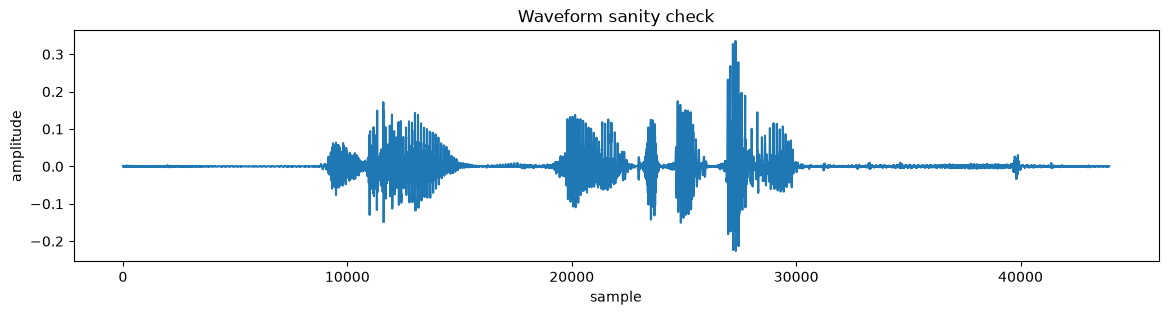

In [15]:
# ============================================================
# 10. WAVEFORM SANITY CHECK
# ============================================================
sample_path = split_files["train"][0]
y, sr = librosa.load(str(sample_path), sr=None, mono=False)

if y.ndim == 1:
    y = y[None, :]

print("File:", sample_path)
print("shape:", y.shape)
print("sr:", sr)
print("duration:", y.shape[-1] / sr)
print("finite:", np.isfinite(y).all())
print("min/max:", y.min(), y.max())
print("mean/std:", y.mean(), y.std())

assert y.shape[-1] > 0
assert np.isfinite(y).all()

plt.figure(figsize=(14,3))
plt.plot(y[0][:min(y.shape[-1], sr*5)])
plt.title("Waveform sanity check")
plt.xlabel("sample")
plt.ylabel("amplitude")
plt.show()

In [16]:
from pathlib import Path

split_dir = PS_ROOT / "database" / "segment_labels"
protocol_dir = PS_ROOT / "database" / "protocols" / "PartialSpoof_LA_cm_protocols"

print("SEGMENT-LABEL FILES")
for split in ["train", "dev", "eval"]:
    for sec in ["0.02", "0.04", "0.08", "0.16", "0.32", "0.64"]:
        p = split_dir / f"{split}_seglab_{sec}.npy"
        print(f"{'FOUND' if p.exists() else 'MISSING'}: {p.name}")

print("\nPROTOCOL DIRECTORY")
print("Exists:", protocol_dir.exists())

if protocol_dir.exists():
    for split in ["train", "dev", "eval"]:
        p = protocol_dir / f"PartialSpoof.LA.cm.{split}.trl.txt"
        print(f"{'FOUND' if p.exists() else 'MISSING'}: {p.name}")

SEGMENT-LABEL FILES
FOUND: train_seglab_0.02.npy
FOUND: train_seglab_0.04.npy
FOUND: train_seglab_0.08.npy
FOUND: train_seglab_0.16.npy
FOUND: train_seglab_0.32.npy
FOUND: train_seglab_0.64.npy
FOUND: dev_seglab_0.02.npy
FOUND: dev_seglab_0.04.npy
FOUND: dev_seglab_0.08.npy
FOUND: dev_seglab_0.16.npy
FOUND: dev_seglab_0.32.npy
FOUND: dev_seglab_0.64.npy
FOUND: eval_seglab_0.02.npy
FOUND: eval_seglab_0.04.npy
FOUND: eval_seglab_0.08.npy
FOUND: eval_seglab_0.16.npy
FOUND: eval_seglab_0.32.npy
FOUND: eval_seglab_0.64.npy

PROTOCOL DIRECTORY
Exists: True
FOUND: PartialSpoof.LA.cm.train.trl.txt
FOUND: PartialSpoof.LA.cm.dev.trl.txt
FOUND: PartialSpoof.LA.cm.eval.trl.txt


In [17]:
# ============================================================
# 13. LABEL ADAPTER — LOAD OFFICIAL PARTIALSPOOF v1.2 LABELS
# ============================================================

EXPECTED_RESOLUTIONS = (20, 40, 80, 160, 320, 640)

def load_official_segment_labels(split):
    """
    Load the official PartialSpoof v1.2 segment-label dictionaries.

    Native files:
      train_seglab_0.01.npy -> 10 ms
      train_seglab_0.02.npy -> 20 ms
      ...
      train_seglab_0.64.npy -> 640 ms
    """

    split_dir = PS_ROOT / "database" / "segment_labels"

    resolution_seconds = {
        20:  "0.02",
        40:  "0.04",
        80:  "0.08",
        160: "0.16",
        320: "0.32",
        640: "0.64",
    }

    loaded = {}

    for ms, sec in resolution_seconds.items():
        path = split_dir / f"{split}_seglab_{sec}.npy"

        if not path.exists():
            raise FileNotFoundError(
                f"Missing official segment-label file: {path}"
            )

        obj = np.load(path, allow_pickle=True)

        # Official files contain a dictionary/defaultdict
        if obj.shape == ():
            data = obj.item()
        else:
            raise RuntimeError(
                f"{split} {ms} ms: unexpected shape {obj.shape}"
            )

        if not isinstance(data, dict):
            raise TypeError(
                f"{split} {ms} ms: expected dict, got {type(data)}"
            )

        loaded[ms] = data

    return loaded


def load_official_utterance_labels(split):
    """
    Read utterance-level labels from the official PartialSpoof
    LA CM protocol file.

    bonafide -> 0
    spoof     -> 1
    """

    protocol_path = (
        PS_ROOT
        / "database"
        / "protocols"
        / "PartialSpoof_LA_cm_protocols"
        / f"PartialSpoof.LA.cm.{split}.trl.txt"
    )

    if not protocol_path.exists():
        raise FileNotFoundError(
            f"Missing official protocol file: {protocol_path}"
        )

    labels = {}

    with open(protocol_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            parts = line.split()

            if len(parts) < 4:
                continue

            utt_id = parts[1]
            label = parts[-1].lower()

            if label == "bonafide":
                labels[utt_id] = 0
            elif label == "spoof":
                labels[utt_id] = 1

    return labels


def build_official_label_map(split):
    """
    Combine the official utterance labels and official
    resolution-wise segment labels.
    """

    segment_maps = load_official_segment_labels(split)
    utterance_labels = load_official_utterance_labels(split)

    # Use the IDs present in the official segment-label file.
    utt_ids = set(segment_maps[20].keys())

    # Make sure every resolution contains the same IDs.
    for ms in EXPECTED_RESOLUTIONS:
        ids = set(segment_maps[ms].keys())

        if ids != utt_ids:
            raise RuntimeError(
                f"{split}: ID mismatch at {ms} ms. "
                f"Expected {len(utt_ids)}, found {len(ids)}."
            )

    missing_utt_labels = sorted(
        utt_id for utt_id in utt_ids
        if utt_id not in utterance_labels
    )

    if missing_utt_labels:
        raise RuntimeError(
            f"{split}: {len(missing_utt_labels)} segment-label IDs "
            "are missing from the official CM protocol."
        )

    label_map = {}

    for utt_id in sorted(utt_ids):
        label_map[utt_id] = {
            "utterance_label": int(utterance_labels[utt_id]),
            "segment_labels": {
                ms: np.asarray(segment_maps[ms][utt_id]).ravel()
                for ms in EXPECTED_RESOLUTIONS
            }
        }

    return label_map


def validate_official_label_map(label_map, split):

    if not isinstance(label_map, dict):
        raise TypeError(f"{split}: label map must be dict")

    missing = []
    bad = []

    for utt_id, record in label_map.items():

        if not isinstance(record, dict):
            bad.append((utt_id, "record_not_dict"))
            continue

        if "utterance_label" not in record:
            bad.append((utt_id, "missing_utterance_label"))

        else:
            if record["utterance_label"] not in [0, 1]:
                bad.append((utt_id, "invalid_utterance_label"))

        seg = record.get("segment_labels")

        if not isinstance(seg, dict):
            bad.append((utt_id, "missing_segment_labels"))
            continue

        for ms in EXPECTED_RESOLUTIONS:

            if ms not in seg:
                missing.append((utt_id, ms))
                continue

            a = np.asarray(seg[ms]).ravel()

            try:
                a_numeric = np.asarray(a, dtype=np.float32)

            except (TypeError, ValueError):
                bad.append((utt_id, f"non_numeric_{ms}"))
                continue

            if len(a_numeric) == 0 or not np.isfinite(a_numeric).all():
                bad.append((utt_id, f"invalid_{ms}"))
                continue

            if not np.isin(a_numeric, [0, 1]).all():
                bad.append((utt_id, f"nonbinary_{ms}"))

    print(f"{split}: records={len(label_map):,}")
    print("missing:", len(missing), "bad:", len(bad))

    if missing[:10]:
        print("missing examples:", missing[:10])

    if bad[:10]:
        print("bad examples:", bad[:10])

    if missing or bad:
        raise RuntimeError(
            f"{split}: official label adapter validation failed. "
            "Fix the adapter before training."
        )

    print("PASS:", split)

# ============================================================
# BUILD OFFICIAL LABEL MAPS
# ============================================================

official_labels = {}

for split in ["train", "dev", "eval"]:

    print("\n" + "=" * 60)
    print(f"BUILDING OFFICIAL LABEL MAP: {split}")
    print("=" * 60)

    official_labels[split] = build_official_label_map(split)

    validate_official_label_map(
        official_labels[split],
        split
    )

print("\n" + "=" * 60)
print("OFFICIAL LABEL ADAPTER READY")
print("=" * 60)

for split in ["train", "dev", "eval"]:
    print(
        split,
        "records =",
        len(official_labels[split])
    )


BUILDING OFFICIAL LABEL MAP: train
train: records=25,380
missing: 0 bad: 0
PASS: train

BUILDING OFFICIAL LABEL MAP: dev
dev: records=24,844
missing: 0 bad: 0
PASS: dev

BUILDING OFFICIAL LABEL MAP: eval
eval: records=71,237
missing: 0 bad: 0
PASS: eval

OFFICIAL LABEL ADAPTER READY
train records = 25380
dev records = 24844
eval records = 71237


In [22]:

# ============================================================
# 14. LABEL POLARITY + CLASS-BALANCE AUDIT
# ============================================================

from collections import Counter
import numpy as np
import pandas as pd

EXPECTED_RESOLUTIONS = (20, 40, 80, 160, 320, 640)


# ------------------------------------------------------------
# 1. DETECT SPOOF LABEL VALUE
# ------------------------------------------------------------

def detect_spoof_value(split="train"):
    bona = Counter()

    for rec in official_labels[split].values():

        if int(rec["utterance_label"]) == 0:

            values, counts = np.unique(
                np.asarray(
                    rec["segment_labels"][20]
                ).ravel().astype(int),
                return_counts=True
            )

            for value, count in zip(values, counts):
                bona[int(value)] += int(count)

    if not bona:
        raise RuntimeError(
            f"No bona-fide segment labels found in {split}."
        )

    bona_value, bona_count = bona.most_common(1)[0]
    purity = bona_count / sum(bona.values())

    print(f"\n[{split}] Bona-fide segment counts: {dict(bona)}")
    print(
        f"[{split}] Most common value: {bona_value} "
        f"(purity {purity:.4%})"
    )

    if purity < 0.99:
        raise RuntimeError(
            f"{split}: bona-fide segment labels are not "
            "consistent enough to infer polarity safely."
        )

    # This inference assumes segment labels are binary
    # and bona-fide frames use the opposite value to spoof.
    if len(bona) > 2 or any(v not in (0, 1) for v in bona):
        raise RuntimeError("Unexpected segment-label values.")

    return 1 - bona_value


SPOOF_VALUE = detect_spoof_value("train")

dev_spoof_value = detect_spoof_value("dev")

assert dev_spoof_value == SPOOF_VALUE, (
    "Train/dev segment-label polarity differs."
)

print(f"\nDetected SPOOF_VALUE = {SPOOF_VALUE}")


# ------------------------------------------------------------
# 2. SEGMENT LABEL MASK
# ------------------------------------------------------------

def spoof_mask(a):
    a = np.asarray(a).ravel().astype(int)
    return a == SPOOF_VALUE


# ------------------------------------------------------------
# 3. UTTERANCE-LEVEL CLASS BALANCE
# ------------------------------------------------------------

def utterance_audit(split):

    recs = official_labels[split]

    n_b = 0
    n_s = 0
    spoof_no_frames = 0
    bona_with_spoof = 0
    ratios = []

    for rec in recs.values():

        mask = spoof_mask(rec["segment_labels"][20])

        if int(rec["utterance_label"]) == 1:
            n_s += 1
            ratios.append(float(mask.mean()))
            spoof_no_frames += int(not mask.any())

        else:
            n_b += 1
            bona_with_spoof += int(mask.any())

    total = n_b + n_s

    print(f"\n[{split}] Bona-fide utterances: {n_b:,}")
    print(f"[{split}] Spoof utterances:     {n_s:,}")
    print(f"[{split}] Spoof share:          {n_s / total:.2%}")
    print(
        f"[{split}] Spoof/bonafide ratio: "
        f"{n_s / max(n_b, 1):.2f}:1"
    )

    print(
        f"[{split}] Spoof utterances with NO spoof frames: "
        f"{spoof_no_frames:,}"
    )

    print(
        f"[{split}] Bona-fide utterances WITH spoof frames: "
        f"{bona_with_spoof:,}"
    )

    print(f"\n[{split}] Spoof-frame fraction within spoof utterances:")

    if ratios:
        print(pd.Series(ratios).describe().round(3).to_string())
    else:
        print("No spoof utterances found.")

    return {
        "bona": n_b,
        "spoof": n_s
    }


UTT_COUNTS = {
    split: utterance_audit(split)
    for split in ("train", "dev")
}


# ------------------------------------------------------------
# 4. SEGMENT-LEVEL CLASS BALANCE
# ------------------------------------------------------------

def segment_class_balance(split):

    rows = []

    for ms in EXPECTED_RESOLUTIONS:

        spoof_count = 0
        bonafide_count = 0

        for rec in official_labels[split].values():

            mask = spoof_mask(rec["segment_labels"][ms])

            spoof_count += int(mask.sum())
            bonafide_count += int((~mask).sum())

        total = spoof_count + bonafide_count

        rows.append({
            "resolution_ms": ms,
            "spoof": spoof_count,
            "bonafide": bonafide_count,
            "spoof_fraction": (
                spoof_count / total if total else 0.0
            )
        })

    df = pd.DataFrame(rows)

    print(f"\n[{split}] Segment-level class balance:")
    display(df)

    return df


train_balance = segment_class_balance("train")

print("\nLABEL POLARITY AND CLASS-BALANCE AUDIT COMPLETED.")



[train] Bona-fide segment counts: {1: 438443}
[train] Most common value: 1 (purity 100.0000%)

[dev] Bona-fide segment counts: {1: 448262}
[dev] Most common value: 1 (purity 100.0000%)

Detected SPOOF_VALUE = 0

[train] Bona-fide utterances: 2,580
[train] Spoof utterances:     22,800
[train] Spoof share:          89.83%
[train] Spoof/bonafide ratio: 8.84:1
[train] Spoof utterances with NO spoof frames: 0
[train] Bona-fide utterances WITH spoof frames: 0

[train] Spoof-frame fraction within spoof utterances:
count    22800.000
mean         0.492
std          0.257
min          0.010
25%          0.272
50%          0.484
75%          0.708
max          1.000

[dev] Bona-fide utterances: 2,548
[dev] Spoof utterances:     22,296
[dev] Spoof share:          89.74%
[dev] Spoof/bonafide ratio: 8.75:1
[dev] Spoof utterances with NO spoof frames: 0
[dev] Bona-fide utterances WITH spoof frames: 0

[dev] Spoof-frame fraction within spoof utterances:
count    22296.000
mean         0.484
std     

,resolution_ms,spoof,bonafide,spoof_fraction
0,20,1929234,2449485,0.440593
1,40,1000486,1195111,0.455678
2,80,536340,567799,0.485754
3,160,303477,254930,0.543469
4,320,181197,104392,0.634468
5,640,112708,36381,0.755978



LABEL POLARITY AND CLASS-BALANCE AUDIT COMPLETED.


# C. Features (cached once)

In [24]:
# ============================================================
# 16. FEATURE FUNCTIONS
# ============================================================
HOP = int(round(cfg.TARGET_SR * cfg.HOP_MS / 1000))
WIN = int(round(cfg.TARGET_SR * cfg.WIN_MS / 1000))

def safe_log(x, eps=1e-7):
    return np.log(np.maximum(x, eps)).astype(np.float32)

def feature_logmel(y, sr):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr,
        n_fft=cfg.N_FFT,
        hop_length=HOP,
        win_length=WIN,
        n_mels=cfg.N_MELS,
        fmin=20,
        fmax=sr/2,
        power=2.0
    )
    return safe_log(S)

def linear_filterbank(sr, n_fft, n_filters):
    freqs = np.linspace(0, sr/2, n_fft//2 + 1)
    edges = np.linspace(0, sr/2, n_filters + 2)
    fb = np.zeros((n_filters, len(freqs)), dtype=np.float32)

    for i in range(n_filters):
        l, c, r = edges[i], edges[i+1], edges[i+2]
        m1 = (freqs >= l) & (freqs <= c)
        m2 = (freqs >= c) & (freqs <= r)
        if c > l:
            fb[i,m1] = (freqs[m1]-l)/(c-l)
        if r > c:
            fb[i,m2] = (r-freqs[m2])/(r-c)

    return fb

def feature_lfcc(y, sr):
    D = np.abs(librosa.stft(
        y,
        n_fft=cfg.N_FFT,
        hop_length=HOP,
        win_length=WIN,
        window="hann"
    ))**2

    fb = linear_filterbank(sr, cfg.N_FFT, cfg.LFCC_FILTERS)
    E = np.maximum(fb @ D, 1e-8)
    logE = np.log(E)

    n = cfg.LFCC_COEFFS
    N = cfg.LFCC_FILTERS
    k = np.arange(n)[:,None]
    m = np.arange(N)[None,:]
    basis = np.cos(np.pi/N * (m+0.5)*k)

    return (basis @ logE).astype(np.float32)

def feature_cqt(y, sr):
    C = np.abs(librosa.cqt(
        y,
        sr=sr,
        hop_length=HOP,
        fmin=cfg.CQT_FMIN,
        bins_per_octave=cfg.CQT_BINS_PER_OCTAVE,
        n_bins=cfg.CQT_N_BINS
    ))
    return safe_log(C)

FEATURE_FUNCS = {
    "logmel": feature_logmel,
    "lfcc": feature_lfcc,
    "cqt": feature_cqt,
}

In [19]:
# Inspect raw official segment labels without changing them

for split in ["train", "dev"]:
    print(f"\n--- {split.upper()} ---")

    recs = official_labels[split]

    bona_id = next(
        utt_id for utt_id, rec in recs.items()
        if rec["utterance_label"] == 0
    )
    spoof_id = next(
        utt_id for utt_id, rec in recs.items()
        if rec["utterance_label"] == 1
    )

    for utt_id, label_type in [
        (bona_id, "bona-fide"),
        (spoof_id, "spoof"),
    ]:
        print(f"\n{label_type} ID: {utt_id}")

        for ms in [20, 40, 80, 160, 320, 640]:
            a = np.asarray(
                recs[utt_id]["segment_labels"][ms]
            ).ravel()

            print(
                f"{ms} ms | dtype={a.dtype} | "
                f"length={len(a)} | "
                f"values/counts={Counter(a.tolist())}"
            )


--- TRAIN ---

bona-fide ID: LA_T_1000406
20 ms | dtype=<U21 | length=143 | values/counts=Counter({'1': 143})
40 ms | dtype=<U21 | length=72 | values/counts=Counter({'1': 72})
80 ms | dtype=<U21 | length=36 | values/counts=Counter({'1': 36})
160 ms | dtype=<U21 | length=18 | values/counts=Counter({'1': 18})
320 ms | dtype=<U21 | length=9 | values/counts=Counter({'1': 9})
640 ms | dtype=<U21 | length=5 | values/counts=Counter({'1': 5})

spoof ID: CON_T_0000000
20 ms | dtype=<U21 | length=138 | values/counts=Counter({'0': 94, '1': 44})
40 ms | dtype=<U21 | length=69 | values/counts=Counter({'0': 48, '1': 21})
80 ms | dtype=<U21 | length=35 | values/counts=Counter({'0': 25, '1': 10})
160 ms | dtype=<U21 | length=18 | values/counts=Counter({'0': 13, '1': 5})
320 ms | dtype=<U21 | length=9 | values/counts=Counter({'0': 7, '1': 2})
640 ms | dtype=<U21 | length=5 | values/counts=Counter({'0': 4, '1': 1})

--- DEV ---

bona-fide ID: LA_D_1024892
20 ms | dtype=<U21 | length=107 | values/counts

In [25]:
# ============================================================
# 18. FEATURE CACHE  (skips files that are already cached WITHOUT re-reading the audio)
# ============================================================
def feature_cache_path(split, utt_id, feature_name, mkdir=False):
    d = CACHE / split / feature_name
    if mkdir:
        d.mkdir(parents=True, exist_ok=True)
    return d / f"{utt_id}.npy"

def prepare_feature_cache(path, split, feature_names):
    utt_id = Path(path).stem
    cps = [feature_cache_path(split, utt_id, n) for n in feature_names]
    if all(cp.exists() for cp in cps):                 # fast path (v2 re-read every wav!)
        return cps

    y, sr = librosa.load(str(path), sr=None, mono=True)
    if sr != cfg.TARGET_SR:
        if not cfg.ALLOW_RESAMPLE:
            raise RuntimeError(f"{path}: sr={sr}, target={cfg.TARGET_SR}, resampling disabled.")
        y = librosa.resample(y, orig_sr=sr, target_sr=cfg.TARGET_SR)
        sr = cfg.TARGET_SR

    for name, cp in zip(feature_names, cps):
        if not cp.exists():
            feat = FEATURE_FUNCS[name](y, sr)
            if not np.isfinite(feat).all():
                raise FloatingPointError(f"{name}: NaN/Inf in {path}")
            feature_cache_path(split, utt_id, name, mkdir=True)
            np.save(cp, feat.astype(np.float32), allow_pickle=False)
    return cps

def precompute_split(split, feature_names, limit=None):
    files = split_files[split] if limit is None else split_files[split][:limit]
    t0 = time.perf_counter()
    for p in tqdm(files, desc=f"Cache {split} {feature_names}"):
        prepare_feature_cache(p, split, feature_names)
    print(f"{split}: {len(files)} files in {(time.perf_counter()-t0)/60:.2f} min")

for _split in ("train", "dev"):
    precompute_split(_split, ("logmel",))

Cache train ('logmel',): 100%|██████████| 25380/25380 [00:04<00:00, 5125.22it/s]


train: 25380 files in 0.08 min


Cache dev ('logmel',): 100%|██████████| 24844/24844 [00:05<00:00, 4825.94it/s]

dev: 24844 files in 0.09 min


In [26]:
# ============================================================
# 19. CACHE VALIDATION
# ============================================================
def validate_cache(split, feature_names, limit=20):
    files = split_files[split][:limit]

    rows = []
    for p in tqdm(files, desc=f"Validate cache {split}"):
        utt_id = p.stem
        for name in feature_names:
            cp = feature_cache_path(split, utt_id, name)
            if not cp.exists():
                rows.append({
                    "utt_id": utt_id,
                    "feature": name,
                    "exists": False,
                    "finite": False,
                    "shape": None
                })
                continue

            x = np.load(cp, mmap_mode="r")
            rows.append({
                "utt_id": utt_id,
                "feature": name,
                "exists": True,
                "finite": np.isfinite(x).all(),
                "shape": x.shape
            })

    df = pd.DataFrame(rows)
    display(df.head(30))

    assert df["exists"].all(), "Missing cache files."
    assert df["finite"].all(), "Non-finite cached feature."

    print("PASS: cache validated.")

validate_cache("train", ("logmel",), limit=32)
validate_cache("dev", ("logmel",), limit=32)

Validate cache train: 100%|██████████| 32/32 [00:00<00:00, 497.92it/s]


,utt_id,feature,exists,finite,shape
0,CON_T_0000000,logmel,True,True,"(80, 275)"
1,CON_T_0000001,logmel,True,True,"(80, 426)"
2,CON_T_0000002,logmel,True,True,"(80, 315)"
3,CON_T_0000003,logmel,True,True,"(80, 597)"
4,CON_T_0000004,logmel,True,True,"(80, 349)"
5,CON_T_0000005,logmel,True,True,"(80, 259)"
6,CON_T_0000006,logmel,True,True,"(80, 271)"
7,CON_T_0000007,logmel,True,True,"(80, 264)"
8,CON_T_0000008,logmel,True,True,"(80, 380)"
9,CON_T_0000009,logmel,True,True,"(80, 297)"


PASS: cache validated.


Validate cache dev: 100%|██████████| 32/32 [00:00<00:00, 519.92it/s]


,utt_id,feature,exists,finite,shape
0,CON_D_0000000,logmel,True,True,"(80, 198)"
1,CON_D_0000001,logmel,True,True,"(80, 501)"
2,CON_D_0000002,logmel,True,True,"(80, 365)"
3,CON_D_0000003,logmel,True,True,"(80, 195)"
4,CON_D_0000004,logmel,True,True,"(80, 199)"
5,CON_D_0000005,logmel,True,True,"(80, 314)"
6,CON_D_0000006,logmel,True,True,"(80, 365)"
7,CON_D_0000007,logmel,True,True,"(80, 204)"
8,CON_D_0000008,logmel,True,True,"(80, 432)"
9,CON_D_0000009,logmel,True,True,"(80, 236)"


PASS: cache validated.


# D. Model (unchanged architecture)

In [27]:
# ============================================================
# 20. MODEL BUILDING BLOCKS
# ============================================================
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.net = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, hidden, 1),
            nn.GELU(),
            nn.Conv2d(hidden, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.net(x)


class ConvTimeBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.1):
        super().__init__()

        self.conv = nn.Conv2d(
            in_ch, out_ch,
            kernel_size=3,
            stride=(2,1),
            padding=1,
            bias=False
        )
        self.bn = nn.BatchNorm2d(out_ch)
        self.se = SEBlock(out_ch)
        self.act = nn.GELU()
        self.drop = nn.Dropout2d(dropout)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.act(x)
        x = self.se(x)
        x = self.drop(x)
        return x


class ViewEncoder(nn.Module):
    def __init__(self, out_dim=128, base=32):
        super().__init__()

        self.blocks = nn.Sequential(
            ConvTimeBlock(1, base),
            ConvTimeBlock(base, base*2),
            ConvTimeBlock(base*2, base*4),
            ConvTimeBlock(base*4, base*4),
        )

        self.proj = nn.Conv1d(base*4, out_dim, 1)

    def forward(self, x):
        # x = B,1,F,T
        z = self.blocks(x)

        # Collapse frequency only.
        z = z.mean(dim=2)

        # B,D,T
        return self.proj(z)


class TCNBlock(nn.Module):
    def __init__(self, dim, dilation, dropout=0.1):
        super().__init__()

        self.conv1 = nn.Conv1d(
            dim, dim, 3,
            padding=dilation,
            dilation=dilation
        )
        self.bn1 = nn.BatchNorm1d(dim)

        self.conv2 = nn.Conv1d(
            dim, dim, 3,
            padding=dilation,
            dilation=dilation
        )
        self.bn2 = nn.BatchNorm1d(dim)

        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        residual = x

        x = self.conv1(x)
        x = self.bn1(x)
        x = F.gelu(x)
        x = self.drop(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = F.gelu(x)
        x = self.drop(x)

        return x + residual


class TemporalBackbone(nn.Module):
    def __init__(self, dim=128):
        super().__init__()

        self.net = nn.Sequential(
            TCNBlock(dim, 1),
            TCNBlock(dim, 2),
            TCNBlock(dim, 4),
            TCNBlock(dim, 8),
        )

    def forward(self, x):
        return self.net(x)

In [28]:
# ============================================================
# 21. FULL MULTI-VIEW / MULTI-RESOLUTION MODEL
# ============================================================
SCALE_MAP = {
    20: 2,
    40: 4,
    80: 8,
    160: 16,
    320: 32,
    640: 64,
}

class PartialSpoofCNN(nn.Module):
    def __init__(
        self,
        feature_names=("logmel",),
        embed_dim=128,
        base=32,
        dropout=0.2,
    ):
        super().__init__()

        self.feature_names = tuple(feature_names)

        self.encoders = nn.ModuleDict({
            name: ViewEncoder(embed_dim, base)
            for name in self.feature_names
        })

        self.fusion = nn.Sequential(
            nn.Conv1d(
                embed_dim * len(self.feature_names),
                embed_dim,
                kernel_size=1
            ),
            nn.BatchNorm1d(embed_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        self.temporal = TemporalBackbone(embed_dim)

        self.utterance_head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(embed_dim, 1)
        )

        self.segment_heads = nn.ModuleDict({
            str(ms): nn.Conv1d(
                embed_dim, 1,
                kernel_size=3,
                padding=1
            )
            for ms in SCALE_MAP
        })

    def encode_views(self, xdict):
        encoded = []

        for name in self.feature_names:
            encoded.append(self.encoders[name](xdict[name]))

        # Explicit temporal alignment.
        T = min(z.shape[-1] for z in encoded)
        encoded = [z[..., :T] for z in encoded]

        return self.fusion(torch.cat(encoded, dim=1))

    def forward(self, xdict, return_segments=True):
        z = self.encode_views(xdict)
        z = self.temporal(z)

        out = {
            "features": z,
            "utt": self.utterance_head(z).squeeze(-1),
        }

        if return_segments:
            seg = {}

            for ms, scale in SCALE_MAP.items():
                usable = (z.shape[-1] // scale) * scale

                if usable == 0:
                    continue

                zz = z[..., :usable]

                # Native temporal grouping.
                pooled = zz.reshape(
                    z.shape[0],
                    z.shape[1],
                    -1,
                    scale
                ).mean(dim=-1)

                seg[ms] = self.segment_heads[str(ms)](pooled).squeeze(1)

            out["seg"] = seg

        return out


def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


model = PartialSpoofCNN(
    feature_names=cfg.DEFAULT_FEATURES,
    embed_dim=cfg.EMBED_DIM,
    base=cfg.BASE_CHANNELS,
    dropout=cfg.DROPOUT,
).to(DEVICE)

print(f"Trainable parameters: {count_parameters(model):,}")

Trainable parameters: 682,483


In [29]:
# ============================================================
# 22. MODEL SHAPE DEBUG
# ============================================================
model.eval()

dummy = {
    "logmel": torch.randn(
        2, 1, cfg.N_MELS, 320,
        device=DEVICE
    )
}

with torch.no_grad():
    out = model(dummy, return_segments=True)

print("utterance:", tuple(out["utt"].shape))

for ms, x in out["seg"].items():
    print(f"{ms} ms:", tuple(x.shape))

assert out["utt"].shape == (2,)
assert all(x.ndim == 2 for x in out["seg"].values())
assert torch.isfinite(out["utt"]).all()
assert all(torch.isfinite(x).all() for x in out["seg"].values())

print("PASS: model forward shape test.")

utterance: (2,)
20 ms: (2, 160)
40 ms: (2, 80)
80 ms: (2, 40)
160 ms: (2, 20)
320 ms: (2, 10)
640 ms: (2, 5)
PASS: model forward shape test.


In [30]:
# ============================================================
# 23. BACKWARD / GRADIENT DEBUG
# ============================================================
model.train()

out = model(dummy, return_segments=True)

debug_loss = out["utt"].mean()
for x in out["seg"].values():
    debug_loss = debug_loss + 0.1 * x.mean()

debug_loss.backward()

grad_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1e9
)

print("debug loss:", float(debug_loss))
print("gradient norm:", float(grad_norm))

assert math.isfinite(float(debug_loss))
assert math.isfinite(float(grad_norm))

model.zero_grad(set_to_none=True)

print("PASS: backward + gradient test.")

debug loss: -0.6629179120063782
gradient norm: 17.301851272583008
PASS: backward + gradient test.


# E. Dataset with label-aware crops, class-balanced sampling, length-sorted evaluation

* **Training**: 4 s crops (400 frames). For spoofed utterances, 70 % of the crops are centred on a spoofed region.
  The **crop label** is computed from the official 20 ms segment labels (≥ 50 ms of spoof inside the crop ⇒ spoof), so a crop that
  contains only bona-fide speech is labelled bona-fide.
* **Class balance**: `WeightedRandomSampler` gives ≈ 50 % bona-fide utterances per batch.
* **Evaluation**: full utterances, length-sorted batches (minimal padding), utterance-level labels.

In [31]:
# ============================================================
# 24. DATASET / SAMPLERS / LOADERS  (v3)
# ============================================================
def normalize_feature(x):
    x = np.asarray(x, dtype=np.float32)
    return ((x - x.mean()) / (x.std() + 1e-6)).astype(np.float32)


def frame_spoof_mask(spoof20, n_frames):
    """20 ms spoof mask -> 10 ms feature-frame mask of length n_frames."""
    m = np.repeat(np.asarray(spoof20, dtype=bool), 2)
    if len(m) < n_frames:
        m = np.concatenate([m, np.full(n_frames - len(m), m[-1] if len(m) else False)])
    return m[:n_frames]


def pick_crop(n_frames, crop_frames, utt_label, frame_mask, spoof_prob, min_spoof, rng):
    """
    Returns (start, length, crop_label).
      * utterance shorter than the crop  -> full utterance, utterance label
      * bona-fide utterance              -> random crop, label 0
      * spoofed utterance                -> with prob `spoof_prob` centre the crop on a spoofed frame;
                                            label = 1 iff >= `min_spoof` spoofed frames fall inside the crop
    """
    if crop_frames is None or n_frames <= crop_frames:
        return 0, n_frames, int(utt_label)

    max_start = n_frames - crop_frames

    if utt_label == 0:
        return int(rng.randint(0, max_start + 1)), crop_frames, 0

    if frame_mask is None or not frame_mask.any():
        # protocol says spoof but segment labels show none: fall back to the utterance label
        return int(rng.randint(0, max_start + 1)), crop_frames, 1

    cs = np.concatenate([[0], np.cumsum(frame_mask.astype(np.int64))])
    spoof_idx = np.flatnonzero(frame_mask)
    start, cnt = 0, 0
    for _ in range(6):                                   # avoid ambiguous 1..min_spoof-1 frame slivers
        if rng.rand() < spoof_prob:
            c = int(spoof_idx[rng.randint(0, len(spoof_idx))])
            start = max(0, min(c - crop_frames // 2, max_start))
        else:
            start = int(rng.randint(0, max_start + 1))
        cnt = int(cs[start + crop_frames] - cs[start])
        if cnt == 0 or cnt >= min_spoof:
            break
    return start, crop_frames, int(cnt >= min_spoof)


class CachedFeatureDataset(Dataset):
    def __init__(self, manifest, split, feature_names, training=False,
                 crop_frames=None, seg_labels=None):
        self.df = manifest.reset_index(drop=True)
        self.utt_ids = self.df["utt_id"].tolist()
        self.utt_labels = self.df["utterance_label"].astype(int).tolist()
        self.split = split
        self.feature_names = tuple(feature_names)
        self.training = training
        self.crop_frames = crop_frames if training else None
        self.spoof20 = {}
        if training and seg_labels is not None:
            for u, l in zip(self.utt_ids, self.utt_labels):
                if l == 1:
                    self.spoof20[u] = spoof_mask(seg_labels[u]["segment_labels"][20])

    def __len__(self):
        return len(self.utt_ids)

    def __getitem__(self, idx):
        u = self.utt_ids[idx]
        y_utt = self.utt_labels[idx]
        views, start, length, y_crop = {}, None, None, y_utt

        for name in self.feature_names:
            cp = feature_cache_path(self.split, u, name)
            if not cp.exists():
                raise FileNotFoundError(f"Missing feature cache: {cp}")
            x = normalize_feature(np.load(cp, allow_pickle=False, mmap_mode="r"))   # full-utterance stats

            if self.crop_frames is not None:
                if start is None:                                # decide once, shared by all views
                    fm = frame_spoof_mask(self.spoof20[u], x.shape[-1]) if u in self.spoof20 else None
                    start, length, y_crop = pick_crop(
                        x.shape[-1], self.crop_frames, y_utt, fm,
                        cfg.SPOOF_CROP_PROB, cfg.MIN_SPOOF_FRAMES_IN_CROP, np.random)
                x = x[:, start:start + length]

            views[name] = torch.from_numpy(np.ascontiguousarray(x[None, ...]))

        return {
            "utt_id": u,
            "views": views,
            "utt": torch.tensor(float(y_crop), dtype=torch.float32),       # label used for training
            "utt_full": torch.tensor(float(y_utt), dtype=torch.float32),   # utterance label (evaluation)
        }


def collate_cached(batch):
    out = {
        "utt_id": [b["utt_id"] for b in batch],
        "utt": torch.stack([b["utt"] for b in batch]),
        "utt_full": torch.stack([b["utt_full"] for b in batch]),
    }
    views = {}
    for name in batch[0]["views"]:
        xs = [b["views"][name] for b in batch]
        max_t = max(x.shape[-1] for x in xs)
        views[name] = torch.stack([F.pad(x, (0, max_t - x.shape[-1])) if x.shape[-1] < max_t else x for x in xs])
    out["views"] = views
    return out


class LengthSortedBatchSampler(Sampler):
    """Deterministic batches of similar length -> almost no padding at evaluation time."""
    def __init__(self, lengths, batch_size):
        order = np.argsort(np.asarray(lengths), kind="stable")
        self.batches = [order[i:i + batch_size].tolist() for i in range(0, len(order), batch_size)]
    def __iter__(self):
        return iter(self.batches)
    def __len__(self):
        return len(self.batches)


_LEN_CACHE = {}
def cached_frame_lengths(manifest, split, feature_name):
    out = []
    for u in tqdm(manifest["utt_id"].tolist(), desc=f"lengths {split}", leave=False):
        key = (split, feature_name, u)
        if key not in _LEN_CACHE:
            _LEN_CACHE[key] = int(np.load(feature_cache_path(split, u, feature_name), mmap_mode="r").shape[-1])
        out.append(_LEN_CACHE[key])
    return out


def build_train_loader(manifest, split, feature_names, samples_per_epoch=None, mode=None, seed=None):
    mode = mode or cfg.IMBALANCE_MODE
    n_total = len(manifest)
    spe = int(samples_per_epoch or cfg.SAMPLES_PER_EPOCH or n_total)
    ds = CachedFeatureDataset(manifest, split, feature_names, training=True,
                              crop_frames=CROP_FRAMES, seg_labels=official_labels[split])
    g = torch.Generator().manual_seed(cfg.SEED if seed is None else seed)

    if mode == "sampler":
        y = np.asarray(ds.utt_labels)
        class_count = np.bincount(y, minlength=2).astype(np.float64)
        weights = (1.0 / class_count)[y]
        sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double),
                                        num_samples=spe, replacement=True, generator=g)
    else:
        sampler = RandomSampler(ds, replacement=(spe > n_total), num_samples=spe, generator=g)

    return DataLoader(ds, batch_size=cfg.BATCH_SIZE, sampler=sampler,
                      num_workers=cfg.NUM_WORKERS,
                      pin_memory=(cfg.PIN_MEMORY and DEVICE.type == "cuda"),
                      collate_fn=collate_cached, drop_last=True)


def build_eval_loader(manifest, split, feature_names, batch_size=None):
    ds = CachedFeatureDataset(manifest, split, feature_names, training=False, crop_frames=None)
    lengths = cached_frame_lengths(manifest, split, feature_names[0])
    bs = LengthSortedBatchSampler(lengths, batch_size or cfg.EVAL_BATCH_SIZE)
    return DataLoader(ds, batch_sampler=bs, num_workers=cfg.NUM_WORKERS,
                      pin_memory=(cfg.PIN_MEMORY and DEVICE.type == "cuda"),
                      collate_fn=collate_cached)


def make_basic_manifest(split):
    rows = []
    for p in split_files[split]:
        u = p.stem
        if u not in official_labels[split]:
            raise KeyError(f"{split}: missing official label for {u}")
        rows.append({"utt_id": u, "audio_path": str(p),
                     "utterance_label": int(official_labels[split][u]["utterance_label"])})
    return pd.DataFrame(rows)


def make_balanced_subset(manifest, per_class, seed=0):
    b = manifest[manifest["utterance_label"] == 0]
    s = manifest[manifest["utterance_label"] == 1]
    n = min(per_class, len(b), len(s))
    return pd.concat([b.sample(n, random_state=seed), s.sample(n, random_state=seed)]).reset_index(drop=True)


train_manifest = make_basic_manifest("train")
dev_manifest = make_basic_manifest("dev")                                  # FULL dev (final evaluation)
dev_epoch_manifest = make_balanced_subset(dev_manifest, cfg.DEV_EPOCH_PER_CLASS)   # per-epoch monitoring

for name, m in (("train", train_manifest), ("dev (full)", dev_manifest), ("dev (per-epoch subset)", dev_epoch_manifest)):
    vc = m["utterance_label"].value_counts().sort_index()
    print(f"{name:24s} bona-fide={vc.get(0,0):6d}  spoof={vc.get(1,0):6d}")

train                    bona-fide=  2580  spoof= 22800
dev (full)               bona-fide=  2548  spoof= 22296
dev (per-epoch subset)   bona-fide=  1500  spoof=  1500


In [32]:
# ============================================================
# SANITY CHECK OF THE FIXES  (must pass before training)
# ============================================================
FEATURES = ("logmel",)
chk_loader = build_train_loader(train_manifest, "train", FEATURES, samples_per_epoch=1600)

crop_lbl, utt_lbl, widths = [], [], []
for i, b in enumerate(chk_loader):
    crop_lbl += b["utt"].tolist(); utt_lbl += b["utt_full"].tolist()
    widths.append(b["views"]["logmel"].shape[-1])
    if i >= 99:
        break

crop_lbl, utt_lbl = np.array(crop_lbl), np.array(utt_lbl)
print("batch tensor shape        :", tuple(b["views"]["logmel"].shape))
print("crop width (frames) max   :", max(widths), " (expected", CROP_FRAMES, ")")
print("utterance-label mean      :", round(float(utt_lbl.mean()), 3), " (v2 was ~0.90; expect ~0.5)")
print("crop-label mean           :", round(float(crop_lbl.mean()), 3))
sp = utt_lbl == 1
print("spoof utts whose crop is labelled spoof:", round(float(crop_lbl[sp].mean()), 3))
print("bona-fide utts labelled spoof          :", int(crop_lbl[~sp].sum()), "(must be 0)")

assert max(widths) == CROP_FRAMES, "crop is not 400 frames - the v2 bug is still present"
assert crop_lbl[~sp].sum() == 0
if cfg.IMBALANCE_MODE == "sampler":
    assert 0.35 < utt_lbl.mean() < 0.65, "sampler did not balance the classes"
print("PASS")

batch tensor shape        : (16, 1, 80, 400)
crop width (frames) max   : 400  (expected 400 )
utterance-label mean      : 0.511  (v2 was ~0.90; expect ~0.5)
crop-label mean           : 0.511
spoof utts whose crop is labelled spoof: 1.0
bona-fide utts labelled spoof          : 0 (must be 0)
PASS


# F. Metrics and training

In [33]:
# ============================================================
# 30. METRICS  (v3: exposes class collapse)
# ============================================================
def compute_eer(y_true, scores):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores).astype(float)
    if len(np.unique(y_true)) < 2:
        return float("nan"), float("nan")
    fpr, tpr, thr = roc_curve(y_true, scores)          # spoof = positive class
    fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fpr - fnr)))
    return float((fpr[i] + fnr[i]) / 2), float(thr[i])


def _rates(y_true, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    bona_rec = tn / max(tn + fp, 1)
    spoof_rec = tp / max(tp + fn, 1)
    return {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "bonafide_recall": float(bona_rec), "spoof_recall": float(spoof_rec),
            "balanced_acc": float((bona_rec + spoof_rec) / 2)}


def utterance_metrics(y_true, scores, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores).astype(float)
    eer, eer_thr = compute_eer(y_true, scores)

    pred05 = (scores >= threshold).astype(int)
    r05 = _rates(y_true, pred05)
    reer = _rates(y_true, (scores >= eer_thr).astype(int))
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred05, average="binary", zero_division=0)

    return {
        "EER": eer, "EER_threshold": eer_thr,
        "ROC_AUC": float(roc_auc_score(y_true, scores)),
        "PR_AUC": float(average_precision_score(y_true, scores)),
        "Accuracy@0.5": float(accuracy_score(y_true, pred05)),
        "Precision@0.5": float(p), "Recall@0.5": float(r), "F1@0.5": float(f1),
        "bonafide_recall@0.5": r05["bonafide_recall"],
        "spoof_recall@0.5": r05["spoof_recall"],
        "balanced_acc@0.5": r05["balanced_acc"],
        "frac_pred_spoof@0.5": float(pred05.mean()),
        "balanced_acc@EER": reer["balanced_acc"],
    }

# quick self-test: a collapsed model must be visible in these metrics
_y = np.array([0]*10 + [1]*90); _s = np.full(100, 0.9) + np.random.rand(100) * 1e-3
_m = utterance_metrics(_y, _s)
assert _m["bonafide_recall@0.5"] == 0.0 and abs(_m["Accuracy@0.5"] - 0.9) < 1e-9
print("metrics self-test OK (a collapsed 90/10 model shows bonafide_recall=0, balanced_acc=0.5)")

metrics self-test OK (a collapsed 90/10 model shows bonafide_recall=0, balanced_acc=0.5)


In [34]:
# ============================================================
# 29/31. TRAINING UTILITIES + TRAIN LOOP (v3)
# ============================================================
def move_views(batch):
    return {k: v.to(DEVICE, non_blocking=True) for k, v in batch["views"].items()}

def gpu_stats():
    if DEVICE.type != "cuda":
        return {}
    return {"allocated_gb": torch.cuda.memory_allocated() / 1024**3,
            "peak_allocated_gb": torch.cuda.max_memory_allocated() / 1024**3}

def save_checkpoint(path, model, optimizer, scheduler, scaler, epoch, metrics, cfg_dict):
    torch.save({"epoch": epoch, "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
                "scaler_state": scaler.state_dict(),
                "metrics": {k: float(v) for k, v in metrics.items()}, "config": cfg_dict}, path)


def train_one_epoch_utt(model, loader, optimizer, scaler, pos_weight=None, epoch=1):
    model.train()
    tot_loss, n_seen, n_pos, n_pred_pos = 0.0, 0, 0.0, 0.0
    t0 = time.perf_counter()
    optimizer.zero_grad(set_to_none=True)

    for step, batch in enumerate(tqdm(loader, desc=f"train ep{epoch:02d}", leave=False)):
        x = move_views(batch)
        y = batch["utt"].to(DEVICE, non_blocking=True)

        if epoch == 1 and step == 0:
            xs = x[next(iter(x))]
            print(f"[first batch] input={tuple(xs.shape)}  label mean={y.mean().item():.2f}  "
                  f"finite={torch.isfinite(xs).all().item()}")

        with torch.amp.autocast(device_type="cuda", enabled=AMP_ENABLED):
            logits = model(x, return_segments=False)["utt"]
        loss = F.binary_cross_entropy_with_logits(logits.float(), y, pos_weight=pos_weight)

        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite loss at step {step}")

        scaler.scale(loss / cfg.GRAD_ACCUM_STEPS).backward()
        if (step + 1) % cfg.GRAD_ACCUM_STEPS == 0:
            scaler.unscale_(optimizer)
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.GRAD_CLIP)
            if not AMP_ENABLED and not torch.isfinite(gn):
                raise FloatingPointError(f"Non-finite gradient norm at step {step}")
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True)

        bs = len(y)
        tot_loss += float(loss.detach()) * bs
        n_seen += bs
        n_pos += float(y.sum())
        n_pred_pos += float((logits.detach() > 0).float().sum())

    el = time.perf_counter() - t0
    return {"loss": tot_loss / max(n_seen, 1), "seconds": el, "samples_per_sec": n_seen / max(el, 1e-6),
            "train_label_mean": n_pos / max(n_seen, 1), "train_pred_spoof_frac": n_pred_pos / max(n_seen, 1)}


@torch.no_grad()
def predict_utterance(model, loader):
    model.eval()
    ys, scores, ids = [], [], []
    for batch in tqdm(loader, desc="predict", leave=False):
        x = move_views(batch)
        with torch.amp.autocast(device_type="cuda", enabled=AMP_ENABLED):
            logits = model(x, return_segments=False)["utt"]
        scores.extend(torch.sigmoid(logits.float()).cpu().numpy())
        ys.extend(batch["utt_full"].numpy())
        ids.extend(batch["utt_id"])
    return np.asarray(ys), np.asarray(scores), ids

In [35]:
# ============================================================
# 36. EXPERIMENT RUNNER (v3)
# ============================================================
def run_utterance_experiment(train_manifest, dev_manifest, feature_names, experiment_name,
                             epochs=None, samples_per_epoch=None, imbalance_mode=None):
    epochs = epochs or cfg.EPOCHS
    spe = samples_per_epoch or cfg.SAMPLES_PER_EPOCH
    mode = imbalance_mode or cfg.IMBALANCE_MODE

    exp_dir = OUT / experiment_name
    exp_dir.mkdir(parents=True, exist_ok=True)
    save_cfg = asdict(cfg)
    save_cfg.update({"feature_names": list(feature_names), "imbalance_mode_used": mode,
                     "crop_frames": CROP_FRAMES, "samples_per_epoch_used": spe, "spoof_value": int(SPOOF_VALUE)})
    json.dump(save_cfg, open(exp_dir / "config.json", "w"), indent=2, default=str)

    train_loader = build_train_loader(train_manifest, "train", feature_names, spe, mode)
    dev_loader = build_eval_loader(dev_manifest, "dev", feature_names)

    pos_weight = None
    if mode == "pos_weight":
        nb = int((train_manifest["utterance_label"] == 0).sum()); ns = int((train_manifest["utterance_label"] == 1).sum())
        pos_weight = torch.tensor(nb / ns, device=DEVICE, dtype=torch.float32)   # spoof is the positive class
        print(f"pos_weight (spoof) = {float(pos_weight):.4f}")
    print(f"[{experiment_name}] imbalance_mode={mode}  samples/epoch={spe}  crop={CROP_FRAMES} frames  batch={cfg.BATCH_SIZE}")

    model = PartialSpoofCNN(feature_names=feature_names, embed_dim=cfg.EMBED_DIM,
                            base=cfg.BASE_CHANNELS, dropout=cfg.DROPOUT).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

    best_eer, best_epoch, bad, history = float("inf"), -1, 0, []

    for epoch in range(1, epochs + 1):
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        tr = train_one_epoch_utt(model, train_loader, optimizer, scaler, pos_weight, epoch)
        scheduler.step()
        y, s, _ = predict_utterance(model, dev_loader)
        m = utterance_metrics(y, s)

        history.append({"epoch": epoch, **m, "train_loss": tr["loss"], "train_label_mean": tr["train_label_mean"],
                        "train_pred_spoof_frac": tr["train_pred_spoof_frac"], "train_seconds": tr["seconds"],
                        "samples_per_sec": tr["samples_per_sec"], "lr": optimizer.param_groups[0]["lr"], **gpu_stats()})
        pd.DataFrame(history).to_csv(exp_dir / "history.csv", index=False)

        print(f"[{experiment_name}] ep={epoch:02d} loss={tr['loss']:.4f} | DEV EER={m['EER']*100:6.2f}% AUC={m['ROC_AUC']:.3f} "
              f"| @0.5: bona-recall={m['bonafide_recall@0.5']:.3f} spoof-recall={m['spoof_recall@0.5']:.3f} "
              f"bal-acc={m['balanced_acc@0.5']:.3f} pred-spoof={m['frac_pred_spoof@0.5']:.2f} "
              f"| {tr['samples_per_sec']:.1f} samples/s")

        if m["frac_pred_spoof@0.5"] > 0.98 or m["frac_pred_spoof@0.5"] < 0.02:
            print("   !! WARNING: model predicts a single class at threshold 0.5 (collapse). "
                  "EER can still be informative, but check the imbalance settings.")

        if m["EER"] < best_eer:
            best_eer, best_epoch, bad = m["EER"], epoch, 0
            save_checkpoint(exp_dir / "best.pt", model, optimizer, scheduler, scaler, epoch, m, save_cfg)
            print("   -> new best checkpoint")
        else:
            bad += 1
            if bad >= cfg.PATIENCE:
                print("Early stopping.")
                break

    print(f"Best DEV EER={best_eer*100:.3f}% at epoch {best_epoch}")
    return pd.DataFrame(history), exp_dir / "best.pt"

# G. Run

1. **Smoke test** (a few minutes). Pass criteria: loss goes down, `pred-spoof` is **not** pinned at 1.00 or 0.00, `bona-recall` > 0.
2. **Full run.**

In [ ]:
# ---- SMOKE TEST: 2 short epochs, small balanced dev subset ----
smoke_dev = make_balanced_subset(dev_manifest, per_class=150, seed=1)
smoke_hist, smoke_ckpt = run_utterance_experiment(
    train_manifest, smoke_dev, ("logmel",), "smoke_v3", epochs=2, samples_per_epoch=800)
display(smoke_hist[["epoch","train_loss","EER","ROC_AUC","bonafide_recall@0.5","spoof_recall@0.5","frac_pred_spoof@0.5"]])

In [36]:
# ---- FULL RUN ----
FEATURES = ("logmel",)
history, best_checkpoint = run_utterance_experiment(
    train_manifest=train_manifest,
    dev_manifest=dev_epoch_manifest,          # class-balanced subset for per-epoch monitoring
    feature_names=FEATURES,
    experiment_name="baseline_logmel_v3",
)
print("Best checkpoint:", best_checkpoint)
display(history[["epoch","train_loss","EER","ROC_AUC","bonafide_recall@0.5","spoof_recall@0.5",
                 "balanced_acc@0.5","frac_pred_spoof@0.5","samples_per_sec"]])

[baseline_logmel_v3] imbalance_mode=sampler  samples/epoch=10000  crop=400 frames  batch=16


train ep01:   0%|          | 0/625 [00:00<?, ?it/s]

[first batch] input=(16, 1, 80, 400)  label mean=0.62  finite=True


[baseline_logmel_v3] ep=01 loss=0.4231 | DEV EER=  9.77% AUC=0.960 | @0.5: bona-recall=0.933 spoof-recall=0.878 bal-acc=0.906 pred-spoof=0.47 | 15.4 samples/s
   -> new best checkpoint


[baseline_logmel_v3] ep=03 loss=0.2295 | DEV EER=  7.87% AUC=0.974 | @0.5: bona-recall=0.973 spoof-recall=0.871 bal-acc=0.922 pred-spoof=0.45 | 15.6 samples/s
   -> new best checkpoint


...

[baseline_logmel_v3] ep=18 loss=0.0689 | DEV EER=  5.00% AUC=0.987 | @0.5: bona-recall=0.947 spoof-recall=0.952 bal-acc=0.949 pred-spoof=0.50 | 14.2 samples/s


[baseline_logmel_v3] ep=19 loss=0.0679 | DEV EER=  5.13% AUC=0.987 | @0.5: bona-recall=0.941 spoof-recall=0.953 bal-acc=0.947 pred-spoof=0.51 | 15.7 samples/s


                                                        it/s]

[baseline_logmel_v3] ep=20 loss=0.0691 | DEV EER=  4.93% AUC=0.987 | @0.5: bona-recall=0.940 spoof-recall=0.954 bal-acc=0.947 pred-spoof=0.51 | 15.9 samples/s
Best DEV EER=4.900% at epoch 17
Best checkpoint: runs\partialspoof_v3\baseline_logmel_v3\best.pt


,epoch,train_loss,EER,ROC_AUC,bonafide_recall@0.5,spoof_recall@0.5,balanced_acc@0.5,frac_pred_spoof@0.5,samples_per_sec
0,1,0.423091,0.097667,0.960152,0.933333,0.878000,0.905667,0.472333,15.390270
1,2,0.276713,0.094000,0.964372,0.934000,0.887333,0.910667,0.476667,15.474675
2,3,0.229493,0.078667,0.973877,0.972667,0.870667,0.921667,0.449000,15.550738
3,4,0.208826,0.076667,0.976936,0.958667,0.902000,0.930333,0.471667,15.366284
4,5,0.180711,0.074000,0.976024,0.925333,0.926667,0.926000,0.500667,15.342638
5,6,0.158185,0.071333,0.977182,0.943333,0.919333,0.931333,0.488000,15.698744
6,7,0.151915,0.065667,0.980956,0.919333,0.939333,0.929333,0.510000,15.735295
7,8,0.131782,0.063333,0.978628,0.947333,0.926667,0.937000,0.489667,15.274175
8,9,0.128695,0.064667,0.979367,0.928667,0.936667,0.932667,0.504000,14.903650
9,10,0.118484,0.058000,0.983877,0.949333,0.934000,0.941667,0.492333,15.339482


In [37]:
from pathlib import Path

ckpt_path = Path(best_checkpoint)
print("Checkpoint exists:", ckpt_path.exists())
print("Checkpoint path:", ckpt_path.resolve())

Checkpoint exists: True
Checkpoint path: C:\Users\Dhanshree\Downloads\runs\partialspoof_v3\baseline_logmel_v3\best.pt


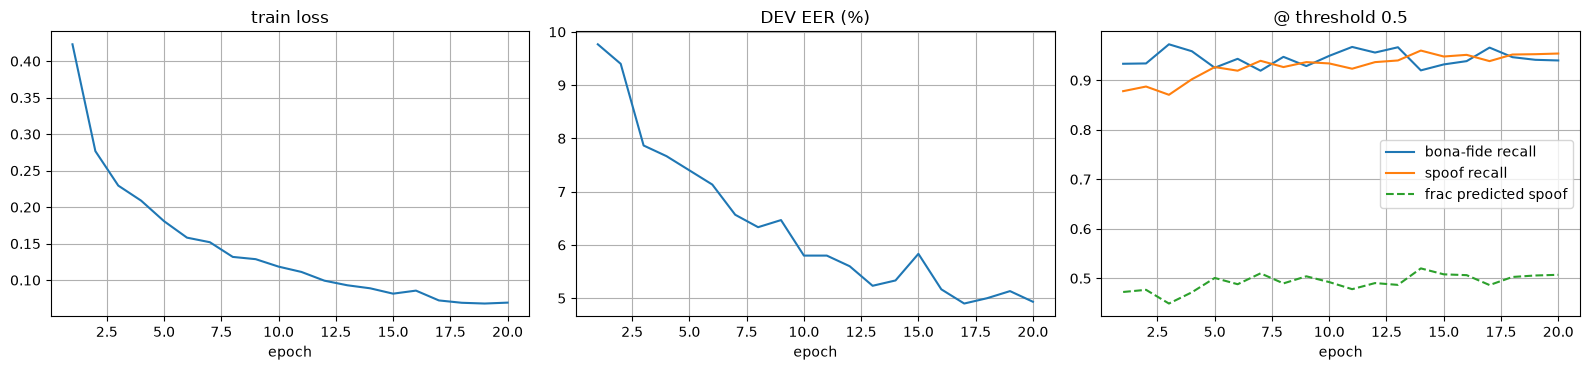

In [38]:
def plot_history(h):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    ax[0].plot(h["epoch"], h["train_loss"]); ax[0].set_title("train loss"); ax[0].grid(True)
    ax[1].plot(h["epoch"], h["EER"] * 100); ax[1].set_title("DEV EER (%)"); ax[1].grid(True)
    ax[2].plot(h["epoch"], h["bonafide_recall@0.5"], label="bona-fide recall")
    ax[2].plot(h["epoch"], h["spoof_recall@0.5"], label="spoof recall")
    ax[2].plot(h["epoch"], h["frac_pred_spoof@0.5"], "--", label="frac predicted spoof")
    ax[2].set_title("@ threshold 0.5"); ax[2].legend(); ax[2].grid(True)
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()

plot_history(history)

# H. Full DEV evaluation of the best checkpoint (+ stratification by spoof ratio)

checkpoint epoch: 17


{
  "EER": 0.0498,
  "EER_threshold": 0.3417,
  "ROC_AUC": 0.9868,
  "PR_AUC": 0.9985,
  "Accuracy@0.5": 0.9403,
  "Precision@0.5": 0.996,
  "Recall@0.5": 0.9372,
  "F1@0.5": 0.9657,
  "bonafide_recall@0.5": 0.9674,
  "spoof_recall@0.5": 0.9372,
  "balanced_acc@0.5": 0.9523,
  "frac_pred_spoof@0.5": 0.8444,
  "balanced_acc@EER": 0.9502
}

Confusion matrix at EER threshold  (rows = true bona-fide / spoof, cols = predicted):
[[ 2421   127]
 [ 1110 21186]]


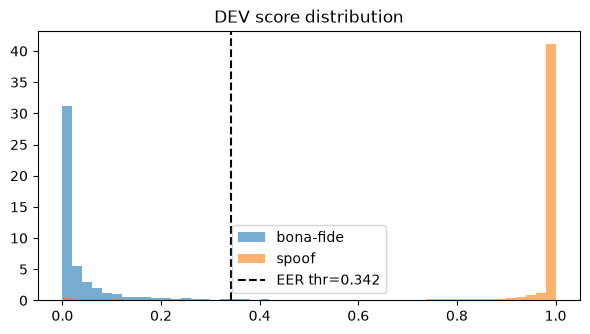


Spoof detection rate by fraction of the utterance that is spoofed:


,detection_rate,count
bin,,
"(-0.001, 0.1]",0.834416,924
"(0.1, 0.25]",0.913686,4194
"(0.25, 0.5]",0.941479,7006
"(0.5, 0.75]",0.976796,5861
"(0.75, 1.0]",0.988634,4311


In [39]:
def evaluate_full_dev(ckpt_path, feature_names=("logmel",)):
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    mdl = PartialSpoofCNN(feature_names=feature_names, embed_dim=cfg.EMBED_DIM,
                          base=cfg.BASE_CHANNELS, dropout=cfg.DROPOUT).to(DEVICE)
    mdl.load_state_dict(ckpt["model_state"])
    print("checkpoint epoch:", ckpt["epoch"])

    loader = build_eval_loader(dev_manifest, "dev", feature_names)       # FULL dev, natural 90/10 prevalence
    y, s, ids = predict_utterance(mdl, loader)
    m = utterance_metrics(y, s)
    print(json.dumps({k: round(v, 4) for k, v in m.items()}, indent=2))

    thr = m["EER_threshold"]
    print("\nConfusion matrix at EER threshold  (rows = true bona-fide / spoof, cols = predicted):")
    print(confusion_matrix(y, (s >= thr).astype(int), labels=[0, 1]))

    plt.figure(figsize=(7, 3.5))
    plt.hist(s[y == 0], bins=50, alpha=.6, label="bona-fide", density=True)
    plt.hist(s[y == 1], bins=50, alpha=.6, label="spoof", density=True)
    plt.axvline(thr, color="k", ls="--", label=f"EER thr={thr:.3f}")
    plt.legend(); plt.title("DEV score distribution"); plt.show()

    # detection rate of spoofed utterances vs. how much of the utterance is spoofed
    df = pd.DataFrame({"utt_id": ids, "y": y, "score": s})
    df["spoof_ratio"] = [float(spoof_mask(official_labels["dev"][u]["segment_labels"][20]).mean()) for u in df["utt_id"]]
    sp = df[df["y"] == 1].copy()
    sp["bin"] = pd.cut(sp["spoof_ratio"], [0, .1, .25, .5, .75, 1.0], include_lowest=True)
    sp["detected@EER"] = sp["score"] >= thr
    print("\nSpoof detection rate by fraction of the utterance that is spoofed:")
    display(sp.groupby("bin", observed=True)["detected@EER"].agg(["mean", "count"]).rename(columns={"mean": "detection_rate"}))
    return m, df

dev_full_metrics, dev_full_scores = evaluate_full_dev(best_checkpoint)

# I. EVAL lock and official metrics
Do not unlock EVAL until the model, features, loss settings and threshold are frozen on DEV.

In [40]:
# ============================================================
# 35. OFFICIAL METRIC CHECK
# ============================================================
metric_dir = PS_ROOT / "PartialSpoof-main" / "metric"

metric_files = {
    "RangeEER": metric_dir / "RangeEER.py",
    "SegmentEER": metric_dir / "SegmentEER.py",
    "UtteranceEER": metric_dir / "UtteranceEER.py",
}

for name, path in metric_files.items():
    print(name, ":", path, "exists=", path.exists())

assert metric_files["RangeEER"].exists()
assert metric_files["SegmentEER"].exists()
assert metric_files["UtteranceEER"].exists()

print("PASS: official metric implementations found.")

RangeEER : D:\PartialSpoofExtract\PartialSpoof-main\metric\RangeEER.py exists= True
SegmentEER : D:\PartialSpoofExtract\PartialSpoof-main\metric\SegmentEER.py exists= True
UtteranceEER : D:\PartialSpoofExtract\PartialSpoof-main\metric\UtteranceEER.py exists= True
PASS: official metric implementations found.


In [41]:
# ============================================================
# 36. INSPECT OFFICIAL METRIC IMPLEMENTATIONS
# ============================================================
for name, path in metric_files.items():
    print(f"\n{'=' * 70}")
    print(f"{name}: {path.name}")
    print("=" * 70)

    source = path.read_text(encoding="utf-8")
    print(source[:12000])


RangeEER: RangeEER.py
#!/usr/bin/env python

# Copyright 2023 National Institute of Informatics (author: Lin Zhang, zhanglin@nii.ac.jp)
# Licensed under the BSD 3-Clause License.

"""
Calculating Range-based EER for spoof localization. 

Lin Zhang, Xin Wang, Erica Cooper, Nicholas Evans, Junichi Yamagishi (2023) 
Range-Based Equal Error Rate for Spoof Localization. Proc. INTERSPEECH 2023, 3212-3216, 
https://www.isca-speech.org/archive/interspeech_2023/zhang23v_interspeech.html

"""

import os
import sys
import argparse
import numpy as np
import pandas as pd
from tqdm import tqdm

import pyannote.metrics.detection 
from pyannote.core import Annotation, Segment, Timeline
from pyannote.database.util import load_rttm

from sandbox import eval_asvspoof
from collections import defaultdict
from scipy.stats import percentileofscore

import rle


parser = argparse.ArgumentParser(add_help=False)
parser.add_argument('--hyp_sco_ali',type=str, 
    help="Path to the predicted score alignment pkl 

In [42]:
# ============================================================
# 39. EVAL SAFETY
# ============================================================
def unlock_eval():
    if not cfg.ALLOW_EVAL:
        raise PermissionError(
            "EVAL LOCKED. Set CFG.ALLOW_EVAL=True only for the final frozen run."
        )

    print(
        "WARNING: EVAL is now unlocked. "
        "Do not use this split for further model decisions."
    )

print("EVAL locked:", not cfg.ALLOW_EVAL)

EVAL locked: True


In [43]:

# ============================================================
# 40. CHECK FINAL EVALUATION CONFIGURATION
# ============================================================
print("EVAL allowed:", cfg.ALLOW_EVAL)
print("Best checkpoint:", best_checkpoint)
print("Checkpoint exists:", Path(best_checkpoint).exists())

assert not cfg.ALLOW_EVAL, "EVAL must remain locked during development."
assert Path(best_checkpoint).exists(), "Best checkpoint file not found."

print("PASS: checkpoint exists and EVAL remains locked.")


EVAL allowed: False
Best checkpoint: runs\partialspoof_v3\baseline_logmel_v3\best.pt
Checkpoint exists: True
PASS: checkpoint exists and EVAL remains locked.


In [44]:
print("Best checkpoint:", best_checkpoint)
print("Checkpoint exists:", Path(best_checkpoint).exists())

ckpt = torch.load(
    best_checkpoint,
    map_location="cpu",
    weights_only=False
)

print("Best epoch:", ckpt.get("epoch"))
print("Checkpoint keys:", list(ckpt.keys()))

Best checkpoint: runs\partialspoof_v3\baseline_logmel_v3\best.pt
Checkpoint exists: True
Best epoch: 17
Checkpoint keys: ['epoch', 'model_state', 'optimizer_state', 'scheduler_state', 'scaler_state', 'metrics', 'config']


# J. Next steps (only after the Log-Mel baseline behaves)
1. Compare `IMBALANCE_MODE` = `"sampler"` vs `"pos_weight"` vs `"none"` (the last should reproduce the v2 failure).
2. Repeat with LFCC and CQT (cache them first with `precompute_split`).
3. Switch on the segment heads with `MultiResolutionLoss` — segment labels are close to balanced (see the audit table), which gives denser, less imbalanced supervision than the utterance label alone.
4. Evaluate localisation with the official `RangeEER.py` / `SegmentEER.py`.
5. Test for VAD/splice-boundary shortcuts and OOD generalisation (LlamaPartialSpoof, Half-Truth).